# Multilabel Bengali Toxicity Classification
### BanglaBERT + BanglaCAT intermediate transfer learning + TF-IDF ensemble

Solution notebook for the **Bengali NLP Safety Challenge 2026**: given a short Bengali / Banglish social-media comment, predict **seven independent binary labels** (`is_toxic`, `implicit_toxicity`, `sarcasm`, `contains_profanity`, `threatening`, `identity_attack`, `sexual_content`).

**Pipeline**

1. Light, conservative text normalisation.
2. Baseline: word + character TF-IDF with one logistic regression per label.
3. **Transfer learning:** adapt BanglaBERT on the external **BanglaCAT** toxicity dataset (12-way classification), keep only the encoder.
4. Fine-tune the adapted encoder on the competition data with a new 7-output head and a class-weighted multilabel BCE loss.
5. Select the transformer checkpoint, the TF-IDF / transformer blend weight and one decision threshold per label on the validation split.
6. Retrain on train + validation, predict the test set, write a submission file.

**Headline validation results** (macro-F1, thresholds tuned per label on the validation split)

| Model | Macro-F1 | Micro-F1 |
|---|---|---|
| TF-IDF + logistic regression | 0.4815 | 0.6272 |
| BanglaBERT (BanglaCAT-adapted encoder) | 0.5488 | 0.6485 |
| **Ensemble (0.45 BanglaBERT + 0.55 TF-IDF)** | **0.5722** | 0.6539 |

> These numbers are selection-time scores: the ensemble weight and thresholds were chosen on the same 500 validation examples they are reported on, so they are optimistic. See *Notes and limitations* at the end.

## 0. Getting the data

The notebook does **not** ship any data. Place the files as follows (or set the `DATA_DIR` environment variable to a different folder):

```text
data/
├── train.csv                 # competition files
├── validation.csv
├── test.csv
├── sample_submission.csv
└── banglacat/
    └── bangla_context_toxicity_train.csv   # BanglaCAT train split
```

**Competition data** — join the *Bengali NLP Safety Challenge 2026* on Kaggle, accept its rules, then either download the files from the competition's *Data* tab or run

```bash
kaggle competitions download -c bengali-nlp-safety-challenge-2026
```

Check the competition rules before redistributing any of the files; this repository should **not** contain them.

**BanglaCAT** — a public Bangla context-aware toxicity dataset distributed through Mendeley Data (search for "BanglaCAT"). Download it, accept its license, and copy only the **train** CSV (`bangla_context_toxicity_train.csv`) into `data/banglacat/`. Cite the dataset according to its Mendeley page. Only the train file is used; the human-annotated test file is never loaded.

**Running on Kaggle:** add both datasets as notebook inputs and set `DATA_DIR` to the competition input folder; copy or symlink the BanglaCAT CSV into `DATA_DIR/banglacat/`.

**Hardware:** the reported results were produced on a single Tesla T4 GPU. A CPU run is possible but impractically slow for the two transformer stages.

In [1]:
# ============================================================
# 1. Imports and reproducibility
# ============================================================
# Optional: pip install -U torch transformers accelerate sentencepiece scikit-learn scipy pandas matplotlib tqdm

import copy
import gc
import json
import os
import random
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 1. Configuration

All paths and hyperparameters are defined in one place. The table summarises the final settings (taken from the configuration cell below).

| Parameter | Value |
|---|---|
| Base model | `csebuetnlp/banglabert` (ELECTRA discriminator; 12 layers, hidden size 768, 32k vocabulary) |
| Encoder used for the competition model | BanglaBERT after BanglaCAT intermediate fine-tuning (`USE_INTERMEDIATE_PRETRAINING = True`) |
| Pooling / head | first-token (`[CLS]`) representation → dropout 0.2 → `Linear(768, 7)` |
| Maximum sequence length | 200 |
| Number of labels | 7 |
| Batch size (train / validation) | 16 / 32 |
| Epochs | 5 (best epoch by validation macro-F1: 4) |
| Optimiser / schedule | AdamW, learning rate 2e-5, weight decay 0.01, linear decay with 10 % warm-up, gradient clipping at 1.0 |
| Loss function | `BCEWithLogitsLoss` with per-label `pos_weight` |
| Class weighting | `pos_weight = (negatives / positives) ** 0.6`, clipped to [0.5, 5.0] |
| TF-IDF branch | word 1–2-grams (≤120k features) + `char_wb` 3–5-grams (≤180k features); per-label logistic regression, `C=4`, `class_weight="balanced"` |
| Validation metric | macro-F1 over the 7 labels, after tuning one threshold per label on the validation split |
| Ensemble | `w · BanglaBERT + (1 − w) · TF-IDF`, `w` searched on a 0.05 grid |
| BanglaCAT stage | 12-way cross-entropy, 2 epochs, batch 32, lr 3e-5, weight decay 0.01, 6 % warm-up, 5 % stratified hold-out |

### Why multilabel (and not multiclass)?

A comment can carry several labels at once — for example a sarcastic remark that is also toxic and attacks an identity group. In the training data the seven positive rates sum to about 1.53, so a typical comment has **more than one** active label. A multiclass softmax forces exactly one class per comment; a **multilabel** setup uses an independent sigmoid per label (`BCEWithLogitsLoss`) so each label is predicted on its own and each can have its own decision threshold.

In [2]:
# ============================================================
# 2. Configuration
# ============================================================

# ---- Paths (see "0. Getting the data") --------------------------
DATA_DIR = Path(os.environ.get("DATA_DIR", "data"))
TRAIN_PATH = DATA_DIR / "train.csv"
VALID_PATH = DATA_DIR / "validation.csv"
TEST_PATH = DATA_DIR / "test.csv"
SAMPLE_SUB_PATH = DATA_DIR / "sample_submission.csv"
BANGLACAT_TRAIN_PATH = DATA_DIR / "banglacat" / "bangla_context_toxicity_train.csv"

OUTPUT_DIR = Path("outputs")      # adapted encoder, submission, config (git-ignored)
FIGURES_DIR = Path("figures")     # result figures (safe to commit)
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# ---- Task -------------------------------------------------------
LABELS = [
    "is_toxic",
    "implicit_toxicity",
    "sarcasm",
    "contains_profanity",
    "threatening",
    "identity_attack",
    "sexual_content",
]

NUM_LABELS = len(LABELS)

MODEL_NAME = "csebuetnlp/banglabert"

MAX_LENGTH = 200
TRAIN_BATCH_SIZE = 16
VALID_BATCH_SIZE = 32

EPOCHS = 5

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10

# Class-aware loss:
# pos_weight = (negative / positive) ** POS_WEIGHT_POWER
# capped to avoid letting the rarest labels dominate training.
POS_WEIGHT_POWER = 0.6
MAX_POS_WEIGHT = 5.0

# TF-IDF settings
WORD_NGRAM_RANGE = (1, 2)
CHAR_NGRAM_RANGE = (3, 5)
WORD_MAX_FEATURES = 120_000
CHAR_MAX_FEATURES = 180_000

# Search grid for ensemble weight.
# 1.0 = transformer only, 0.0 = TF-IDF only.
ENSEMBLE_WEIGHTS = np.arange(0.0, 1.01, 0.05)

# Fine threshold grid (0.01 steps); matters for rare labels.
THRESHOLD_GRID = np.arange(0.05, 0.951, 0.01)

# ---- BanglaCAT intermediate transfer learning -------------------
# Set to False to skip the BanglaCAT stage and fine-tune the raw
# public checkpoint instead (useful for an on/off comparison).
USE_INTERMEDIATE_PRETRAINING = True

INTERMEDIATE_MAX_LENGTH = 200
INTERMEDIATE_BATCH_SIZE = 32
INTERMEDIATE_EPOCHS = 2
INTERMEDIATE_LEARNING_RATE = 3e-5
INTERMEDIATE_WEIGHT_DECAY = 0.01
INTERMEDIATE_WARMUP_RATIO = 0.06
INTERMEDIATE_VAL_FRACTION = 0.05   # hold-out slice of BanglaCAT train, for monitoring only

INTERMEDIATE_ENCODER_DIR = OUTPUT_DIR / "banglabert_banglacat_adapted"

print("Labels:", NUM_LABELS)
print("Model:", MODEL_NAME)
print("Intermediate pretraining enabled:", USE_INTERMEDIATE_PRETRAINING)

Labels: 7
Model: csebuetnlp/banglabert
Intermediate pretraining enabled: True


## 2. Dataset loading

The competition files are read from the paths above and checked against the expected schema (`ID`, `text`, seven 0/1 label columns). Only aggregate statistics are shown — no raw comments are printed in this notebook.

The label distribution is heavily imbalanced (`is_toxic` ≈ 71 % positive vs. `threatening` ≈ 3 %), which motivates the class-weighted loss, the balanced logistic regressions and the per-label thresholds used later.

In [3]:
# ============================================================
# 3. Load + validate data
# ============================================================

for path in [TRAIN_PATH, VALID_PATH, TEST_PATH, SAMPLE_SUB_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. See section 0 ('Getting the data') or set the DATA_DIR environment variable."
        )

train_df = pd.read_csv(TRAIN_PATH)
valid_df = pd.read_csv(VALID_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_SUB_PATH)

expected_train = ["ID", "text"] + LABELS
expected_test = ["ID", "text"]
expected_sub = ["ID"] + LABELS

for name, df, cols in [
    ("train", train_df, expected_train),
    ("validation", valid_df, expected_train),
    ("test", test_df, expected_test),
    ("sample_submission", sample_submission, expected_sub),
]:
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Test:", test_df.shape)

print("\nTraining label distribution:")
dist = pd.DataFrame({
    "positive": train_df[LABELS].sum(),
    "positive_rate": train_df[LABELS].mean(),
})
display(dist.sort_values("positive_rate", ascending=False).round(4))

Train: (3297, 9)
Validation: (500, 9)
Test: (1000, 2)



Training label distribution:


,positive,positive_rate
is_toxic,2357,0.7149
identity_attack,1379,0.4183
sarcasm,566,0.1717
contains_profanity,367,0.1113
sexual_content,159,0.0482
implicit_toxicity,110,0.0334
threatening,93,0.0282


## 3. Text preprocessing

Normalisation is deliberately **conservative**: only whitespace is collapsed and trimmed. Bengali script, Latin-script Banglish, digits and punctuation are all kept, and nothing is transliterated or spell-corrected, because spelling variants, elongations and punctuation are useful signals for toxic and sarcastic text. The same function is also applied to BanglaCAT text so both datasets reach the model in the same form.

In [ ]:
# ============================================================
# 4. Conservative text normalization
# ============================================================

def normalize_text(text):
    if pd.isna(text):
        return ""
    text = str(text)

    # Keep Bengali, Latin, numbers and punctuation.
    # Do NOT transliterate or remove punctuation:
    # punctuation and spelling variants can be useful safety signals.
    text = re.sub(r"\s+", " ", text)
    return text.strip()

for df in [train_df, valid_df, test_df]:
    df["clean_text"] = df["text"].map(normalize_text)

## 4. Baseline: TF-IDF + logistic regression

The dataset has only a few thousand training examples and mixes Bengali script, Banglish and noisy spelling. Two model families are therefore combined:

- **Word + character TF-IDF with logistic regression** captures surface and sub-word spelling patterns (profanity variants, transliterations).
- **BanglaBERT** captures context, which matters for sarcasm and implicit toxicity.

Their errors differ, so averaging their probabilities can help. This section trains the TF-IDF branch (one logistic regression per label) on the training split and tunes one decision threshold per label on the validation split; the threshold helpers are reused for every model below.

In [5]:
# ============================================================
# 5. TF-IDF model — validation split
# ============================================================

X_train_text = train_df["clean_text"].values
X_valid_text = valid_df["clean_text"].values
X_test_text = test_df["clean_text"].values

word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=WORD_NGRAM_RANGE,
    min_df=2,
    max_df=0.995,
    max_features=WORD_MAX_FEATURES,
    sublinear_tf=True,
)

char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=CHAR_NGRAM_RANGE,
    min_df=2,
    max_features=CHAR_MAX_FEATURES,
    sublinear_tf=True,
)

X_train_word = word_vectorizer.fit_transform(X_train_text)
X_valid_word = word_vectorizer.transform(X_valid_text)

X_train_char = char_vectorizer.fit_transform(X_train_text)
X_valid_char = char_vectorizer.transform(X_valid_text)

X_train_tfidf = hstack([X_train_word, X_train_char], format="csr")
X_valid_tfidf = hstack([X_valid_word, X_valid_char], format="csr")

y_train = train_df[LABELS].to_numpy(dtype=np.int32)
y_valid = valid_df[LABELS].to_numpy(dtype=np.int32)

tfidf_models = {}

for i, label in enumerate(LABELS):
    print(f"[{i+1}/{NUM_LABELS}] TF-IDF: {label}")

    clf = LogisticRegression(
        C=4.0,
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED,
    )
    clf.fit(X_train_tfidf, y_train[:, i])
    tfidf_models[label] = clf

tfidf_valid_probs = np.column_stack([
    tfidf_models[label].predict_proba(X_valid_tfidf)[:, 1]
    for label in LABELS
])

print("TF-IDF validation probability shape:", tfidf_valid_probs.shape)

[1/7] TF-IDF: is_toxic
[2/7] TF-IDF: implicit_toxicity
[3/7] TF-IDF: sarcasm
[4/7] TF-IDF: contains_profanity
[5/7] TF-IDF: threatening
[6/7] TF-IDF: identity_attack
[7/7] TF-IDF: sexual_content
TF-IDF validation probability shape: (500, 7)


In [6]:
# ============================================================
# 6. Threshold tuning helpers
# ============================================================

def tune_per_label_thresholds(y_true, probs, labels, grid=THRESHOLD_GRID):
    thresholds = []
    rows = []

    for i, label in enumerate(labels):
        best_t = 0.50
        best_f1 = -1.0

        for t in grid:
            pred = (probs[:, i] >= t).astype(int)
            score = f1_score(y_true[:, i], pred, zero_division=0)

            if score > best_f1:
                best_f1 = score
                best_t = float(t)

        thresholds.append(best_t)
        rows.append({
            "label": label,
            "threshold": best_t,
            "f1": best_f1,
        })

    return np.array(thresholds), pd.DataFrame(rows)

def apply_thresholds(probs, thresholds):
    return (probs >= np.asarray(thresholds).reshape(1, -1)).astype(int)

def evaluate_probs(y_true, probs, thresholds):
    pred = apply_thresholds(probs, thresholds)
    return {
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "micro_f1": f1_score(y_true, pred, average="micro", zero_division=0),
        "weighted_f1": f1_score(y_true, pred, average="weighted", zero_division=0),
        "samples_f1": f1_score(y_true, pred, average="samples", zero_division=0),
    }

tfidf_thresholds, tfidf_threshold_df = tune_per_label_thresholds(
    y_valid, tfidf_valid_probs, LABELS
)

tfidf_metrics = evaluate_probs(
    y_valid, tfidf_valid_probs, tfidf_thresholds
)

print("TF-IDF metrics:", {k: round(v, 4) for k, v in tfidf_metrics.items()})
display(tfidf_threshold_df.round(4))

TF-IDF metrics: {'macro_f1': 0.4815, 'micro_f1': 0.6272, 'weighted_f1': 0.6758, 'samples_f1': 0.4823}


,label,threshold,f1
0,is_toxic,0.36,0.8602
1,implicit_toxicity,0.27,0.2857
2,sarcasm,0.19,0.3243
3,contains_profanity,0.44,0.5217
4,threatening,0.15,0.1887
5,identity_attack,0.31,0.6296
6,sexual_content,0.35,0.5600


## 5. External Dataset and Transfer Learning

**What was done.** BanglaCAT, a public Bangla toxicity dataset, was used as an external source of toxicity-related text for **intermediate-task transfer learning** (STILTs-style): BanglaBERT is first fine-tuned on BanglaCAT and the resulting *encoder* is then used to initialise the competition model.

1. Only BanglaCAT's **train** split is loaded (19,453 rows). Its human-annotated test split is never touched.
2. Each row is a `(previous_reply, target_reply)` pair; only `target_reply` is used, because the competition data consists of single comments.
3. BanglaCAT's hierarchical labels are joined into one **12-way single-label target** (`Non-toxic | None` plus 11 toxic sub-types such as `Insult`, `Threat`, `Hate Speech`, `Profanity`).
4. BanglaBERT plus a temporary 12-way linear head is trained with cross-entropy for 2 epochs. A stratified 5 % slice of BanglaCAT is held out only to monitor this stage.
5. Only the **encoder weights** are saved. The 12-way head is discarded.
6. The competition model is built on that adapted encoder, with a **new, randomly initialised 7-output head** trained from scratch on the competition data with a multilabel BCE loss.

**Label spaces differ.** BanglaCAT's 12 single-label classes do not map onto the competition's 7 independent labels (`implicit_toxicity`, for example, has no counterpart). No label mapping is attempted: the external data only shapes the encoder's representations, and the final classification head and training objective belong entirely to the target task.

**What was *not* done.** No masked-language-model pretraining, no joint training on both datasets, and no use of BanglaCAT labels as features. This notebook also does **not** contain a with/without-BanglaCAT comparison, so the benefit of this stage on the competition task is *not measured here* (set `USE_INTERMEDIATE_PRETRAINING = False` and re-run to measure it). BanglaCAT's train split is described in its documentation as LLM-generated and human-checked rather than scraped social-media text, so its style may differ from the noisy competition data.

In [7]:
# ============================================================
# 7. Load BanglaCAT (train split only)
# ============================================================

if USE_INTERMEDIATE_PRETRAINING:
    if not BANGLACAT_TRAIN_PATH.exists():
        raise FileNotFoundError(
            f"{BANGLACAT_TRAIN_PATH} not found. See section 0 ('Getting the data'), "
            "or set USE_INTERMEDIATE_PRETRAINING = False to skip this stage."
        )

    # keep_default_na=False is required: BanglaCAT stores the literal
    # string "None" for non-toxic toxicity_type, not a blank/NaN.
    banglacat_df = pd.read_csv(
        BANGLACAT_TRAIN_PATH, encoding="utf-8-sig", keep_default_na=False
    )

    assert (banglacat_df["level_1_class"].eq("Non-toxic") == banglacat_df["toxicity_type"].eq("None")).all(), \
        "BanglaCAT hierarchy invariant (Non-toxic <=> toxicity_type=None) does not hold — check the file."

    banglacat_df["cat_label"] = banglacat_df["level_1_class"] + " | " + banglacat_df["toxicity_type"]
    banglacat_df["cat_clean_text"] = banglacat_df["target_reply"].map(normalize_text)

    CAT_CLASSES = sorted(banglacat_df["cat_label"].unique().tolist())
    CAT_LABEL2ID = {c: i for i, c in enumerate(CAT_CLASSES)}
    banglacat_df["cat_label_id"] = banglacat_df["cat_label"].map(CAT_LABEL2ID)

    print("BanglaCAT rows:", len(banglacat_df))
    print("Classes:", len(CAT_CLASSES))
    display(banglacat_df["cat_label"].value_counts().to_frame("count"))

    # Small stratified held-out slice purely to monitor this stage — not
    # used anywhere else and not the same as the competition's valid_df.
    cat_train_df, cat_holdout_df = train_test_split(
        banglacat_df,
        test_size=INTERMEDIATE_VAL_FRACTION,
        random_state=SEED,
        stratify=banglacat_df["cat_label_id"],
    )
    print("BanglaCAT internal split -> train:", len(cat_train_df), "holdout:", len(cat_holdout_df))

BanglaCAT rows: 19453
Classes: 12

,count
cat_label,
Non-toxic | None,9861
Toxic | Insult,1923
Toxic | Threat,902
Toxic | Mockery / Ridicule,845
Toxic | Hate Speech,808
Toxic | Identity Attack,800
Toxic | Incitement / Encouragement of Harm,800
Toxic | Dehumanization,796
Toxic | Profanity,779


BanglaCAT internal split -> train: 18480 holdout: 973

In [8]:
# ============================================================
# 8. Fine-tune BanglaBERT on BanglaCAT's 12-way label (encoder adaptation only)
# ============================================================

if USE_INTERMEDIATE_PRETRAINING:
    cat_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    class BanglaCATDataset(Dataset):
        def __init__(self, dataframe, tokenizer, max_length):
            self.texts = dataframe["cat_clean_text"].fillna("").astype(str).tolist()
            self.labels = dataframe["cat_label_id"].to_numpy(dtype=np.int64)
            self.tokenizer = tokenizer
            self.max_length = max_length

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, idx):
            enc = self.tokenizer(
                self.texts[idx],
                truncation=True,
                max_length=self.max_length,
                padding="max_length",
                return_tensors="pt",
            )
            item = {k: v.squeeze(0) for k, v in enc.items()}
            item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
            return item

    cat_train_loader = DataLoader(
        BanglaCATDataset(cat_train_df, cat_tokenizer, INTERMEDIATE_MAX_LENGTH),
        batch_size=INTERMEDIATE_BATCH_SIZE, shuffle=True, num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )
    cat_holdout_loader = DataLoader(
        BanglaCATDataset(cat_holdout_df, cat_tokenizer, INTERMEDIATE_MAX_LENGTH),
        batch_size=INTERMEDIATE_BATCH_SIZE * 2, shuffle=False, num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    class BanglaCATClassifier(torch.nn.Module):
        def __init__(self, encoder, hidden_size, num_classes, dropout=0.2):
            super().__init__()
            self.encoder = encoder
            self.dropout = torch.nn.Dropout(dropout)
            self.classifier = torch.nn.Linear(hidden_size, num_classes)

        def forward(self, input_ids, attention_mask, token_type_ids=None):
            kwargs = {"input_ids": input_ids, "attention_mask": attention_mask}
            if token_type_ids is not None:
                kwargs["token_type_ids"] = token_type_ids
            outputs = self.encoder(**kwargs)
            pooled = outputs.last_hidden_state[:, 0]
            return self.classifier(self.dropout(pooled))

    cat_encoder = AutoModel.from_pretrained(MODEL_NAME)
    cat_model = BanglaCATClassifier(
        cat_encoder, cat_encoder.config.hidden_size, len(CAT_CLASSES)
    ).to(DEVICE)

    cat_criterion = torch.nn.CrossEntropyLoss()
    cat_optimizer = torch.optim.AdamW(
        cat_model.parameters(), lr=INTERMEDIATE_LEARNING_RATE, weight_decay=INTERMEDIATE_WEIGHT_DECAY
    )
    cat_total_steps = len(cat_train_loader) * INTERMEDIATE_EPOCHS
    cat_scheduler = get_linear_schedule_with_warmup(
        cat_optimizer,
        num_warmup_steps=int(cat_total_steps * INTERMEDIATE_WARMUP_RATIO),
        num_training_steps=cat_total_steps,
    )

    for epoch in range(INTERMEDIATE_EPOCHS):
        cat_model.train()
        total_loss = 0.0
        for batch in tqdm(cat_train_loader, desc=f"BanglaCAT epoch {epoch+1}/{INTERMEDIATE_EPOCHS}"):
            labels = batch.pop("labels").to(DEVICE)
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            cat_optimizer.zero_grad(set_to_none=True)
            logits = cat_model(**batch)
            loss = cat_criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(cat_model.parameters(), 1.0)
            cat_optimizer.step()
            cat_scheduler.step()
            total_loss += loss.item()

        cat_model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for batch in cat_holdout_loader:
                labels = batch.pop("labels").to(DEVICE)
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                logits = cat_model(**batch)
                preds = logits.argmax(dim=-1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        print(f"Epoch {epoch+1}: train loss {total_loss/len(cat_train_loader):.4f}, "
              f"holdout accuracy {correct/total:.4f}")

    # Only the encoder is saved; the 12-way BanglaCAT head is discarded.
    INTERMEDIATE_ENCODER_DIR.mkdir(parents=True, exist_ok=True)
    cat_model.encoder.save_pretrained(INTERMEDIATE_ENCODER_DIR)
    cat_tokenizer.save_pretrained(INTERMEDIATE_ENCODER_DIR)
    print("Saved adapted encoder to:", INTERMEDIATE_ENCODER_DIR)

    # Free GPU memory before the competition model is built.
    del cat_model, cat_encoder, cat_optimizer, cat_scheduler, cat_train_loader, cat_holdout_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Epoch 1: train loss 0.3554, holdout accuracy 0.9938

Epoch 2: train loss 0.0379, holdout accuracy 0.9918

Saved adapted encoder to: outputs/banglabert_banglacat_adapted

The hold-out accuracy above only measures how well the encoder learned BanglaCAT's *own* 12-way task; it says nothing about performance on the competition labels, which are evaluated in the sections below.

## 6. Tokenizer, model architecture and class weights

**Architecture** — `MultiLabelBanglaBERT`:

```text
text → BanglaBERT tokenizer (max_length=200, padded) → ELECTRA encoder (BanglaCAT-adapted)
     → first-token hidden state (768-d) → dropout(0.2) → Linear(768 → 7) → 7 logits
```

Probabilities are `sigmoid(logits)`, one per label. The encoder is fully fine-tuned (no frozen layers).

**Loss** — `BCEWithLogitsLoss` with a per-label `pos_weight` to counter the label imbalance. Raw inverse-frequency weights would let the rarest labels dominate, so the ratio is softened with an exponent of 0.6 and clipped at 5.0; the table below shows the resulting weights. `is_toxic`, which is the majority class, is even down-weighted (0.58).

In [9]:
# ============================================================
# 9. Tokenizer, dataset, model and class weights
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class ToxicityDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length, labels=None):
        self.texts = dataframe["clean_text"].fillna("").astype(str).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.labels = None if labels is None else dataframe[labels].to_numpy(dtype=np.float32)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_length,
            padding="max_length",
            return_tensors="pt",
        )

        item = {k: v.squeeze(0) for k, v in enc.items()}

        if self.labels is not None:
            item["labels"] = torch.tensor(self.labels[idx], dtype=torch.float32)

        return item

train_ds = ToxicityDataset(train_df, tokenizer, MAX_LENGTH, LABELS)
valid_ds = ToxicityDataset(valid_df, tokenizer, MAX_LENGTH, LABELS)

train_loader = DataLoader(
    train_ds,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

valid_loader = DataLoader(
    valid_ds,
    batch_size=VALID_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

ENCODER_SOURCE = str(INTERMEDIATE_ENCODER_DIR) if USE_INTERMEDIATE_PRETRAINING else MODEL_NAME
print("Loading competition-model encoder from:", ENCODER_SOURCE)
model = AutoModel.from_pretrained(ENCODER_SOURCE)

hidden_size = model.config.hidden_size

class MultiLabelBanglaBERT(torch.nn.Module):
    def __init__(self, encoder, hidden_size, num_labels, dropout=0.2):
        super().__init__()
        self.encoder = encoder
        self.dropout = torch.nn.Dropout(dropout)
        self.classifier = torch.nn.Linear(hidden_size, num_labels)

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        kwargs = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
        }
        if token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids

        outputs = self.encoder(**kwargs)

        # BanglaBERT is BERT/ELECTRA-like. Use the first token representation.
        pooled = outputs.last_hidden_state[:, 0]
        logits = self.classifier(self.dropout(pooled))
        return logits

model = MultiLabelBanglaBERT(
    model,
    hidden_size,
    NUM_LABELS,
).to(DEVICE)

# Moderated class weights.
positive_counts = train_df[LABELS].sum().to_numpy(dtype=np.float64)
negative_counts = len(train_df) - positive_counts

raw_ratio = negative_counts / np.maximum(positive_counts, 1)
pos_weight = np.power(raw_ratio, POS_WEIGHT_POWER)
pos_weight = np.clip(pos_weight, 0.5, MAX_POS_WEIGHT)

pos_weight_tensor = torch.tensor(
    pos_weight, dtype=torch.float32, device=DEVICE
)

print("Positive class weights:")
display(pd.DataFrame({
    "label": LABELS,
    "positive_count": positive_counts.astype(int),
    "negative_count": negative_counts.astype(int),
    "pos_weight": pos_weight,
}).round(3))

Loading competition-model encoder from: outputs/banglabert_banglacat_adapted

Positive class weights:

,label,positive_count,negative_count,pos_weight
0,is_toxic,2357,940,0.576
1,implicit_toxicity,110,3187,5.000
2,sarcasm,566,2731,2.571
3,contains_profanity,367,2930,3.478
4,threatening,93,3204,5.000
5,identity_attack,1379,1918,1.219
6,sexual_content,159,3138,5.000


## 7. Training configuration and loop

Each epoch trains on the training split, predicts the validation split, re-tunes the seven thresholds on those predictions and computes macro-F1. The epoch with the best validation macro-F1 is kept (`best_state`) and restored at the end.

In [10]:
# ============================================================
# 10. Transformer training / validation functions
# ============================================================

criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

def train_one_epoch(model, loader, optimizer, scheduler):
    model.train()
    total_loss = 0.0

    for batch in tqdm(loader, desc="Training"):
        labels = batch.pop("labels").to(DEVICE)

        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        optimizer.zero_grad(set_to_none=True)

        logits = model(**batch)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    return total_loss / max(len(loader), 1)

@torch.no_grad()
def predict_loader(model, loader, with_labels=True):
    model.eval()

    all_probs = []
    all_labels = []

    for batch in tqdm(loader, desc="Inference"):
        labels = batch.pop("labels", None)

        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        logits = model(**batch)
        probs = torch.sigmoid(logits).cpu().numpy()

        all_probs.append(probs)

        if labels is not None:
            all_labels.append(labels.numpy())

    probs = np.vstack(all_probs)

    if all_labels:
        return probs, np.vstack(all_labels).astype(int)

    return probs

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

print("Total steps:", total_steps)
print("Warmup steps:", warmup_steps)

Total steps: 1035
Warmup steps: 103


In [11]:
# ============================================================
# 11. Train BanglaBERT and select best validation checkpoint
# ============================================================

best_macro = -1.0
best_state = None
history = []

for epoch in range(EPOCHS):
    print(f"\n{'='*65}")
    print(f"Epoch {epoch+1}/{EPOCHS}")
    print(f"{'='*65}")

    train_loss = train_one_epoch(
        model, train_loader, optimizer, scheduler
    )

    valid_probs, valid_labels_from_loader = predict_loader(
        model, valid_loader, with_labels=True
    )

    # Tune thresholds on validation after every epoch.
    epoch_thresholds, epoch_threshold_df = tune_per_label_thresholds(
        y_valid,
        valid_probs,
        LABELS,
    )

    metrics = evaluate_probs(
        y_valid,
        valid_probs,
        epoch_thresholds,
    )

    print(f"Train loss : {train_loss:.4f}")
    print(f"Macro F1   : {metrics['macro_f1']:.4f}")
    print(f"Micro F1   : {metrics['micro_f1']:.4f}")
    print(f"Weighted F1: {metrics['weighted_f1']:.4f}")

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **metrics,
    })

    if metrics["macro_f1"] > best_macro:
        best_macro = metrics["macro_f1"]
        best_state = copy.deepcopy(model.state_dict())
        best_transformer_thresholds = epoch_thresholds.copy()
        best_transformer_probs = valid_probs.copy()

        print("✓ New best checkpoint")

# Restore best checkpoint.
model.load_state_dict(best_state)
model.to(DEVICE)

history_df = pd.DataFrame(history)
display(history_df.round(4))

print("Best transformer validation macro-F1:", round(best_macro, 4))
print("Best thresholds:")
display(pd.DataFrame({
    "label": LABELS,
    "threshold": best_transformer_thresholds,
}).round(3))


Epoch 1/5


Train loss : 0.6013
Macro F1   : 0.4575
Micro F1   : 0.6355
Weighted F1: 0.6816
✓ New best checkpoint

Epoch 2/5


Train loss : 0.4936
Macro F1   : 0.5278
Micro F1   : 0.6718
Weighted F1: 0.7086
✓ New best checkpoint

Epoch 3/5


Train loss : 0.4331
Macro F1   : 0.5439
Micro F1   : 0.6396
Weighted F1: 0.7079
✓ New best checkpoint

Epoch 4/5


Train loss : 0.3879
Macro F1   : 0.5488
Micro F1   : 0.6485
Weighted F1: 0.7048
✓ New best checkpoint

Epoch 5/5


Train loss : 0.3599
Macro F1   : 0.5435
Micro F1   : 0.6443
Weighted F1: 0.7028


,epoch,train_loss,macro_f1,micro_f1,weighted_f1,samples_f1
0,1,0.6013,0.4575,0.6355,0.6816,0.4904
1,2,0.4936,0.5278,0.6718,0.7086,0.5167
2,3,0.4331,0.5439,0.6396,0.7079,0.4973
3,4,0.3879,0.5488,0.6485,0.7048,0.5004
4,5,0.3599,0.5435,0.6443,0.7028,0.5017


Best transformer validation macro-F1: 0.5488
Best thresholds:


,label,threshold
0,is_toxic,0.18
1,implicit_toxicity,0.28
2,sarcasm,0.14
3,contains_profanity,0.47
4,threatening,0.49
5,identity_attack,0.38
6,sexual_content,0.36


### Training curves

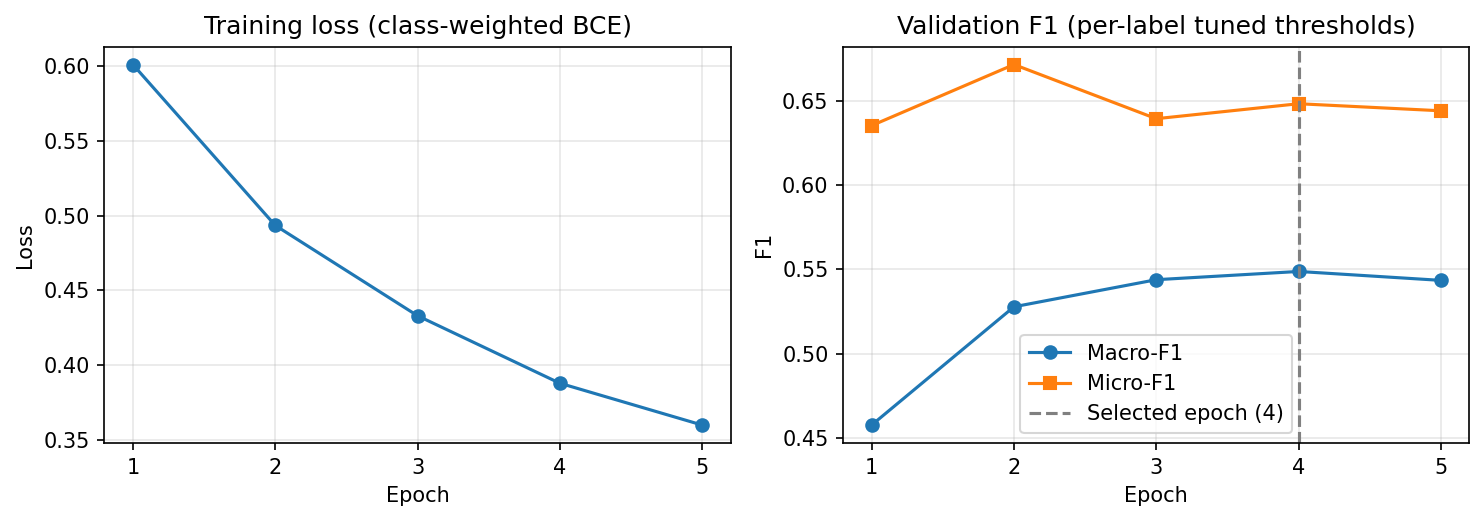

In [12]:
FIGURES_DIR.mkdir(exist_ok=True)

best_epoch = int(history_df.loc[history_df["macro_f1"].idxmax(), "epoch"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o")
axes[0].set(title="Training loss (class-weighted BCE)", xlabel="Epoch", ylabel="Loss")

axes[1].plot(history_df["epoch"], history_df["macro_f1"], marker="o", label="Macro-F1")
axes[1].plot(history_df["epoch"], history_df["micro_f1"], marker="s", label="Micro-F1")
axes[1].axvline(best_epoch, linestyle="--", color="grey", label=f"Selected epoch ({best_epoch})")
axes[1].set(title="Validation F1 (per-label tuned thresholds)", xlabel="Epoch", ylabel="F1")
axes[1].legend()

for ax in axes:
    ax.set_xticks(history_df["epoch"])
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Training loss falls steadily, while validation macro-F1 peaks at epoch 4 (0.549) and slightly declines at epoch 5, so epoch 4's weights are the ones used for the ensemble search.

### Model comparison

In [13]:
# ============================================================
# 12. Compare TF-IDF vs Transformer
# ============================================================

transformer_metrics = evaluate_probs(
    y_valid,
    best_transformer_probs,
    best_transformer_thresholds,
)

comparison = pd.DataFrame([
    {"model": "TF-IDF", **tfidf_metrics},
    {"model": "BanglaBERT", **transformer_metrics},
])

display(comparison.round(4))

,model,macro_f1,micro_f1,weighted_f1,samples_f1
0,TF-IDF,0.4815,0.6272,0.6758,0.4823
1,BanglaBERT,0.5488,0.6485,0.7048,0.5004


## 8. Ensemble search and thresholds

Rather than assuming that an ensemble helps, the blend is **measured** on the validation split. For each weight `w`:

```text
p = w · BanglaBERT + (1 − w) · TF-IDF
```

the seven thresholds are re-tuned on `p` and macro-F1 is computed. The best `w` and its thresholds are used for the final predictions. The blend (0.45 / 0.55) beats both single models.

In [14]:
# ============================================================
# 13. Search ensemble weight + thresholds
# ============================================================

ensemble_results = []

best_ensemble = {
    "macro_f1": -1.0,
    "weight": None,
    "thresholds": None,
    "probs": None,
}

for w in ENSEMBLE_WEIGHTS:
    ensemble_probs = (
        w * best_transformer_probs
        + (1.0 - w) * tfidf_valid_probs
    )

    thresholds, threshold_df = tune_per_label_thresholds(
        y_valid,
        ensemble_probs,
        LABELS,
    )

    metrics = evaluate_probs(
        y_valid,
        ensemble_probs,
        thresholds,
    )

    row = {
        "transformer_weight": float(w),
        "tfidf_weight": float(1.0 - w),
        **metrics,
    }
    ensemble_results.append(row)

    if metrics["macro_f1"] > best_ensemble["macro_f1"]:
        best_ensemble = {
            "macro_f1": metrics["macro_f1"],
            "weight": float(w),
            "thresholds": thresholds.copy(),
            "probs": ensemble_probs.copy(),
        }

ensemble_results_df = pd.DataFrame(ensemble_results).sort_values(
    "macro_f1", ascending=False
)

display(ensemble_results_df.head(10).round(4))

print("BEST ENSEMBLE")
print("Transformer weight:", best_ensemble["weight"])
print("TF-IDF weight:", 1.0 - best_ensemble["weight"])
print("Macro F1:", round(best_ensemble["macro_f1"], 4))

display(pd.DataFrame({
    "label": LABELS,
    "threshold": best_ensemble["thresholds"],
}).round(3))

,transformer_weight,tfidf_weight,macro_f1,micro_f1,weighted_f1,samples_f1
9,0.45,0.55,0.5722,0.6539,0.7093,0.4974
10,0.50,0.50,0.5709,0.6502,0.7090,0.4980
11,0.55,0.45,0.5697,0.6517,0.7107,0.4932
12,0.60,0.40,0.5697,0.6598,0.7105,0.5010
13,0.65,0.35,0.5661,0.6555,0.7111,0.4965
15,0.75,0.25,0.5655,0.6491,0.7123,0.4991
14,0.70,0.30,0.5653,0.6484,0.7101,0.4960
16,0.80,0.20,0.5628,0.6549,0.7107,0.4981
17,0.85,0.15,0.5601,0.6582,0.7090,0.5013
8,0.40,0.60,0.5593,0.6674,0.7053,0.5055


BEST ENSEMBLE
Transformer weight: 0.45
TF-IDF weight: 0.55
Macro F1: 0.5722


,label,threshold
0,is_toxic,0.37
1,implicit_toxicity,0.23
2,sarcasm,0.20
3,contains_profanity,0.41
4,threatening,0.29
5,identity_attack,0.33
6,sexual_content,0.45


### Final validation report

In [15]:
# ============================================================
# 14. Detailed validation report for chosen ensemble
# ============================================================

best_valid_predictions = apply_thresholds(
    best_ensemble["probs"],
    best_ensemble["thresholds"],
)

report = classification_report(
    y_valid,
    best_valid_predictions,
    target_names=LABELS,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).T

display(
    report_df.loc[
        LABELS,
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

final_validation_metrics = evaluate_probs(
    y_valid,
    best_ensemble["probs"],
    best_ensemble["thresholds"],
)

print("\nChosen validation metrics:")
for k, v in final_validation_metrics.items():
    print(f"{k:12s}: {v:.4f}")

,precision,recall,f1-score,support
is_toxic,0.8202,0.9433,0.8775,353.0
implicit_toxicity,0.2000,0.4667,0.2800,15.0
sarcasm,0.2088,0.8636,0.3363,88.0
contains_profanity,0.5316,0.7636,0.6269,55.0
threatening,0.5625,0.6000,0.5806,15.0
identity_attack,0.5246,0.8578,0.6511,211.0
sexual_content,0.6400,0.6667,0.6531,24.0



Chosen validation metrics:
macro_f1    : 0.5722
micro_f1    : 0.6539
weighted_f1 : 0.7093
samples_f1  : 0.4974


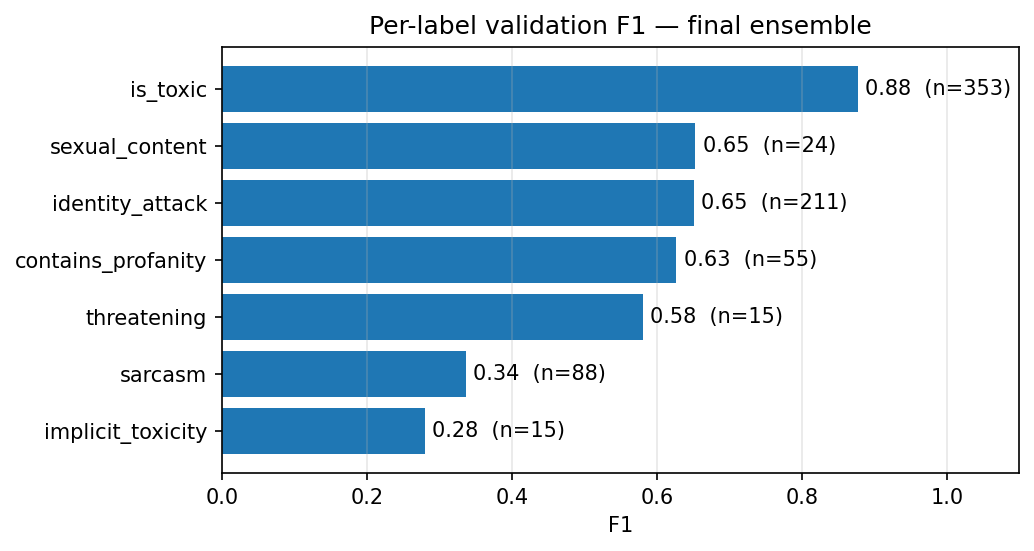

In [16]:
per_label = report_df.loc[LABELS, ["f1-score", "support"]].sort_values("f1-score")

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.barh(per_label.index, per_label["f1-score"])
for bar, (_, row) in zip(bars, per_label.iterrows()):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{row['f1-score']:.2f}  (n={int(row['support'])})", va="center")

ax.set(xlim=(0, 1.1), xlabel="F1", title="Per-label validation F1 — final ensemble")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "per_label_f1.png", dpi=150, bbox_inches="tight")
plt.show()

`is_toxic` is predicted well (F1 ≈ 0.88). The rare and subjective labels are much harder: `implicit_toxicity` (F1 0.28, 15 validation positives) and `sarcasm` (0.34, precision only 0.21) are the weakest. Several labels trade precision for high recall because the thresholds optimise F1 on very few positives; with 15–24 positives per rare label, these per-label scores are noisy.

## 9. Final training on train + validation

Once the checkpoint, blend weight and thresholds have been chosen, both branches are retrained on **all 3,797 labelled examples** (3,297 train + 500 validation) and applied to the test set. The TF-IDF vectorisers and classifiers are refit from scratch. The final BanglaBERT starts from the **same BanglaCAT-adapted encoder** that was validated, with a fresh head, and is trained for the full 5 epochs with the same hyperparameters (class weights are recomputed on the combined data). The thresholds and blend weight from the validation experiment are reused as-is.

In [17]:
# ============================================================
# 15. Final TF-IDF model on train + validation
# ============================================================

full_df = pd.concat(
    [
        train_df[["ID", "clean_text"] + LABELS],
        valid_df[["ID", "clean_text"] + LABELS],
    ],
    ignore_index=True,
)

X_full_text = full_df["clean_text"].values
X_test_text = test_df["clean_text"].values
y_full = full_df[LABELS].to_numpy(dtype=np.int32)

final_word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=WORD_NGRAM_RANGE,
    min_df=2,
    max_df=0.995,
    max_features=WORD_MAX_FEATURES,
    sublinear_tf=True,
)

final_char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=CHAR_NGRAM_RANGE,
    min_df=2,
    max_features=CHAR_MAX_FEATURES,
    sublinear_tf=True,
)

X_full_word = final_word_vectorizer.fit_transform(X_full_text)
X_test_word = final_word_vectorizer.transform(X_test_text)

X_full_char = final_char_vectorizer.fit_transform(X_full_text)
X_test_char = final_char_vectorizer.transform(X_test_text)

X_full_tfidf = hstack(
    [X_full_word, X_full_char],
    format="csr",
)

X_test_tfidf = hstack(
    [X_test_word, X_test_char],
    format="csr",
)

final_tfidf_models = {}

for i, label in enumerate(LABELS):
    print(f"[{i+1}/{NUM_LABELS}] Final TF-IDF: {label}")

    clf = LogisticRegression(
        C=4.0,
        max_iter=3000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED,
    )

    clf.fit(X_full_tfidf, y_full[:, i])
    final_tfidf_models[label] = clf

final_tfidf_test_probs = np.column_stack([
    final_tfidf_models[label].predict_proba(X_test_tfidf)[:, 1]
    for label in LABELS
])

print("Final TF-IDF test probabilities:", final_tfidf_test_probs.shape)

[1/7] Final TF-IDF: is_toxic
[2/7] Final TF-IDF: implicit_toxicity
[3/7] Final TF-IDF: sarcasm
[4/7] Final TF-IDF: contains_profanity
[5/7] Final TF-IDF: threatening
[6/7] Final TF-IDF: identity_attack
[7/7] Final TF-IDF: sexual_content
Final TF-IDF test probabilities: (1000, 7)


In [18]:
# ============================================================
# 16. Final BanglaBERT on all labelled data
# ============================================================

# Free GPU memory from validation model objects where possible.
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

full_ds = ToxicityDataset(
    full_df,
    tokenizer,
    MAX_LENGTH,
    LABELS,
)

full_loader = DataLoader(
    full_ds,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

# Reuse the SAME encoder checkpoint the validation-stage model was built
# from (ENCODER_SOURCE, set in the transformer-setup cell), not the raw
# MODEL_NAME — otherwise the model you validated and the model you submit
# with silently diverge.
print("Final model encoder source:", ENCODER_SOURCE)
final_model = MultiLabelBanglaBERT(
    AutoModel.from_pretrained(ENCODER_SOURCE),
    hidden_size,
    NUM_LABELS,
).to(DEVICE)

# Recompute class weights on all labelled data.
full_positive = y_full.sum(axis=0).astype(np.float64)
full_negative = len(y_full) - full_positive

full_ratio = full_negative / np.maximum(full_positive, 1)
full_pos_weight = np.power(full_ratio, POS_WEIGHT_POWER)
full_pos_weight = np.clip(full_pos_weight, 0.5, MAX_POS_WEIGHT)

final_criterion = torch.nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        full_pos_weight,
        dtype=torch.float32,
        device=DEVICE,
    )
)

final_optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

final_total_steps = len(full_loader) * EPOCHS
final_warmup_steps = int(final_total_steps * WARMUP_RATIO)

final_scheduler = get_linear_schedule_with_warmup(
    final_optimizer,
    num_warmup_steps=final_warmup_steps,
    num_training_steps=final_total_steps,
)

print("Final training examples:", len(full_df))
print("Final training steps:", final_total_steps)

Final model encoder source: outputs/banglabert_banglacat_adapted

Final training examples: 3797
Final training steps: 1190

In [19]:
# ============================================================
# 17. Train final BanglaBERT
# ============================================================

final_model.train()

for epoch in range(EPOCHS):
    total_loss = 0.0

    print(f"\nFinal epoch {epoch+1}/{EPOCHS}")

    for batch in tqdm(full_loader, desc="Final training"):
        labels = batch.pop("labels").to(DEVICE)
        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        final_optimizer.zero_grad(set_to_none=True)

        logits = final_model(**batch)
        loss = final_criterion(logits, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(final_model.parameters(), 1.0)

        final_optimizer.step()
        final_scheduler.step()

        total_loss += loss.item()

    print("Loss:", round(total_loss / len(full_loader), 4))

_ = final_model.eval()


Final epoch 1/5


Loss: 0.6122

Final epoch 2/5


Loss: 0.4953

Final epoch 3/5


Loss: 0.4372

Final epoch 4/5


Loss: 0.3934

Final epoch 5/5


Loss: 0.3653


## 10. Test prediction and submission file

Test probabilities from the two final models are blended with the validated weight, thresholded per label and written to a CSV in the format of `sample_submission.csv`. Only aggregate counts are displayed.

In [20]:
# ============================================================
# 18. Final test predictions + ensemble
# ============================================================

test_ds = ToxicityDataset(
    test_df,
    tokenizer,
    MAX_LENGTH,
    labels=None,
)

test_loader = DataLoader(
    test_ds,
    batch_size=VALID_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

final_transformer_test_probs = predict_loader(
    final_model,
    test_loader,
    with_labels=False,
)

print("BanglaBERT test probabilities:", final_transformer_test_probs.shape)

transformer_weight = best_ensemble["weight"]
tfidf_weight = 1.0 - transformer_weight

final_ensemble_test_probs = (
    transformer_weight * final_transformer_test_probs
    + tfidf_weight * final_tfidf_test_probs
)

final_predictions = apply_thresholds(
    final_ensemble_test_probs,
    best_ensemble["thresholds"],
)

print("Prediction shape:", final_predictions.shape)

submission_upgraded = pd.DataFrame({
    "ID": test_df["ID"].values
})

for i, label in enumerate(LABELS):
    submission_upgraded[label] = final_predictions[:, i]

submission_upgraded = submission_upgraded[["ID"] + LABELS]

BanglaBERT test probabilities: (1000, 7)
Prediction shape: (1000, 7)


In [21]:
# ============================================================
# 19. Validate submission + save artifacts
# ============================================================

assert len(submission_upgraded) == len(test_df)
assert submission_upgraded["ID"].tolist() == test_df["ID"].tolist()
assert list(submission_upgraded.columns) == ["ID"] + LABELS

for label in LABELS:
    assert set(submission_upgraded[label].unique()).issubset({0, 1})

submission_path = OUTPUT_DIR / "submission.csv"
submission_upgraded.to_csv(submission_path, index=False)

# Save thresholds / ensemble settings.
config = {
    "model_name": MODEL_NAME,
    "use_intermediate_pretraining": USE_INTERMEDIATE_PRETRAINING,
    "encoder_source": ENCODER_SOURCE,
    "max_length": MAX_LENGTH,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "pos_weight_power": POS_WEIGHT_POWER,
    "max_pos_weight": MAX_POS_WEIGHT,
    "transformer_weight": transformer_weight,
    "tfidf_weight": tfidf_weight,
    "thresholds": {
        label: float(t)
        for label, t in zip(LABELS, best_ensemble["thresholds"])
    },
    "validation_metrics": {
        k: float(v) for k, v in final_validation_metrics.items()
    },
}

config_path = OUTPUT_DIR / "model_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Saved:", submission_path)
print("Saved:", config_path)
print("\nValidation macro-F1 used for model selection:",
      round(final_validation_metrics["macro_f1"], 4))
print("\nFinal positive prediction counts:")
display(submission_upgraded[LABELS].sum().sort_values(ascending=False).to_frame("predicted_positive"))

,predicted_positive
is_toxic,811
sarcasm,730
identity_attack,725
contains_profanity,159
implicit_toxicity,78
sexual_content,56
threatening,37


## 11. Notes and limitations

- **Optimistic validation scores.** The transformer checkpoint, blend weight and all seven thresholds were selected on the same 500-example validation split that the metrics are reported on. The reported macro-F1 of 0.572 is therefore an upper-leaning estimate; the competition's hidden test score is the unbiased measure. Rare labels have only 15–24 validation positives, so their thresholds and F1 values are noisy.
- **BanglaCAT benefit not isolated.** The BanglaCAT-adapted encoder was used in all reported transformer results, but this notebook has no BanglaCAT-off run. Set `USE_INTERMEDIATE_PRETRAINING = False` and re-run sections 6–8 to quantify its contribution (ideally with several seeds, given the small validation set).
- **Final model uses a fixed 5 epochs.** The validation run peaked at epoch 4; the retrained model on train + validation uses all 5 epochs because no held-out data remains for checkpoint selection.
- **Domain gap.** BanglaCAT text is not the same distribution as the competition's noisy Banglish comments.
- **Content warning / data handling.** The data contains toxic, abusive and sexual language. No raw records are included in this notebook's outputs; keep it that way when sharing, and follow the competition and BanglaCAT licence terms.

**Files written by this notebook** (under `outputs/` and `figures/`): the BanglaCAT-adapted encoder, `submission.csv`, `model_config.json` (blend weight, thresholds, hyperparameters, validation metrics), and the two result figures.